<a href="https://colab.research.google.com/github/vencov/FAV_upsidedown/blob/main/SDT/EX_sdt_interactive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Signal detection theory: interactive demo

Equal-variance Gaussian model:

- noise only: $x \sim \mathcal{N}(0,1)$
- signal + noise: $x \sim \mathcal{N}(d',1)$
- the listener answers YES if $x > \lambda$

Quantities:

- hit rate $H = 1-\Phi(\lambda-d')$, false-alarm rate $F = 1-\Phi(\lambda)$
- sensitivity $d' = z(H) - z(F)$
- criterion $c = -\tfrac12[z(H)+z(F)] = \lambda - d'/2$ ($c<0$ liberal, $c>0$ conservative)
- area under the ROC curve $\mathrm{AUC} = \Phi(d'/\sqrt2)$

where $\Phi$ is the standard normal CDF and $z=\Phi^{-1}$.

In [1]:
# In Colab/Jupyter, install if needed: !pip install ipywidgets
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import ipywidgets as widgets
from IPython.display import display

def rates(dprime, c):
    """Hit and false-alarm rate for given d' and criterion c (relative to the midpoint)."""
    lam = c + dprime / 2
    return 1 - norm.cdf(lam - dprime), 1 - norm.cdf(lam)   # H, F

def dprime_c(H, F):
    zH, zF = norm.ppf(H), norm.ppf(F)
    return zH - zF, -0.5 * (zH + zF)

def plot_sdt(dprime, c, title=None, axes=None):
    lam = c + dprime / 2
    H, F = rates(dprime, c)
    x = np.linspace(-4, 8, 600)
    if axes is None:
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    ax1, ax2 = axes

    # left: distributions
    ax1.plot(x, norm.pdf(x, 0, 1), color='tab:blue', label='noise')
    ax1.plot(x, norm.pdf(x, dprime, 1), color='tab:red', label='signal + noise')
    ax1.fill_between(x[x > lam], norm.pdf(x[x > lam], 0, 1), color='tab:blue', alpha=0.35, label=f'FA = {F:.2f}')
    ax1.fill_between(x[x > lam], norm.pdf(x[x > lam], dprime, 1), color='tab:red', alpha=0.25, label=f'hit = {H:.2f}')
    ax1.axvline(lam, color='k', lw=2)
    ax1.axvline(dprime / 2, color='gray', ls=':', lw=1)
    ax1.text(lam, 0.43, r' $\lambda$', ha='left')
    ax1.set_xlabel('internal response x'); ax1.set_ylabel('probability density')
    ax1.set_ylim(0, 0.48); ax1.legend(loc='upper left', fontsize=8)
    ax1.set_title(title or f"d' = {dprime:.2f},  c = {c:.2f}")

    # right: ROC
    lams = np.linspace(-6, 10, 400)
    for d in [0, 1, 2, 3]:
        ax2.plot(1 - norm.cdf(lams), 1 - norm.cdf(lams - d), color='0.8', lw=1, label=f"d'={d}")
    ax2.plot(1 - norm.cdf(lams), 1 - norm.cdf(lams - dprime), color='tab:green', lw=2)
    ax2.plot([F], [H], 'o', color='k', ms=8)
    ax2.plot([0, 1], [0, 1], 'k--', lw=0.8)
    ax2.legend(loc='lower right', fontsize=7, title='reference curves', title_fontsize=7)
    ax2.set_xlabel('false alarm rate F'); ax2.set_ylabel('hit rate H')
    ax2.set_xlim(0, 1); ax2.set_ylim(0, 1); ax2.set_aspect('equal')
    auc = norm.cdf(dprime / np.sqrt(2))
    ax2.set_title(f"ROC: H = {H:.2f}, F = {F:.2f}, AUC = {auc:.2f}")
    return axes


## 1. Explore: change sensitivity $d'$ and criterion $c$

Move $c$ and watch the ROC point slide **along one curve**. Move $d'$ and the curve itself changes.

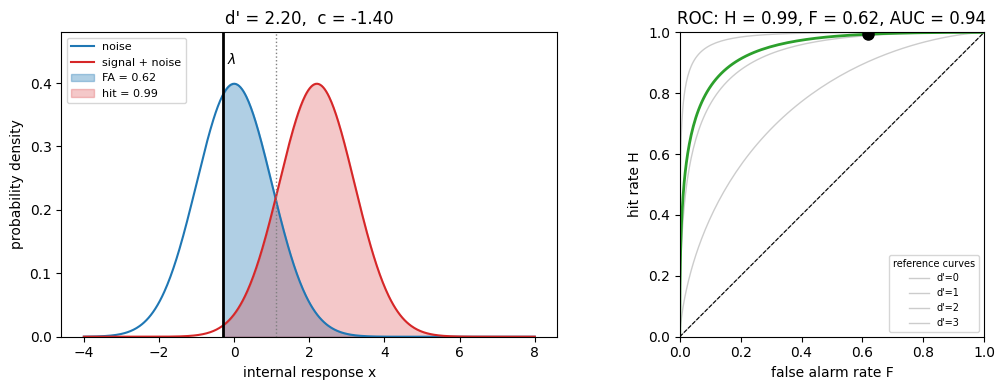

In [2]:
def explore(dprime=2.0, c=0.0):
    plot_sdt(dprime, c)
    plt.tight_layout(); plt.show()

widgets.interact(
    explore,
    dprime=widgets.FloatSlider(value=2.0, min=0.0, max=4.0, step=0.1, description="d'", continuous_update=True),
    c=widgets.FloatSlider(value=0.0, min=-2.0, max=2.0, step=0.1, description='c', continuous_update=True),
);

## 2. From data to $d'$ and $c$

Enter the number of hits, misses, false alarms and correct rejections. Rates of exactly 0 or 1 are corrected to $1/(2N)$ and $1-1/(2N)$, where $N$ is the number of signal (or noise) trials.

In [3]:
def from_counts(hits=84, misses=16, false_alarms=16, correct_rejections=84):
    Ns, Nn = hits + misses, false_alarms + correct_rejections
    H = np.clip(hits / Ns, 1 / (2 * Ns), 1 - 1 / (2 * Ns))
    F = np.clip(false_alarms / Nn, 1 / (2 * Nn), 1 - 1 / (2 * Nn))
    d, c = dprime_c(H, F)
    print(f"H = {H:.3f}, F = {F:.3f}  ->  d' = {d:.2f}, c = {c:.2f}  ({'liberal' if c < -0.05 else 'conservative' if c > 0.05 else 'about unbiased'})")
    plot_sdt(d, c)
    plt.tight_layout(); plt.show()

widgets.interact(
    from_counts,
    hits=widgets.IntSlider(value=84, min=0, max=200, description='hits'),
    misses=widgets.IntSlider(value=16, min=0, max=200, description='misses'),
    false_alarms=widgets.IntSlider(value=16, min=0, max=200, description='FA'),
    correct_rejections=widgets.IntSlider(value=84, min=0, max=200, description='CR'),
);

interactive(children=(IntSlider(value=84, description='hits', max=200), IntSlider(value=16, description='misse…

## 3. Same sensitivity, different strategy (the two listeners from the slides)

Listener 1: H = 0.84, F = 0.16  ->  d' = 1.99, c = -0.00
Listener 2: H = 0.93, F = 0.31  ->  d' = 1.97, c = -0.49


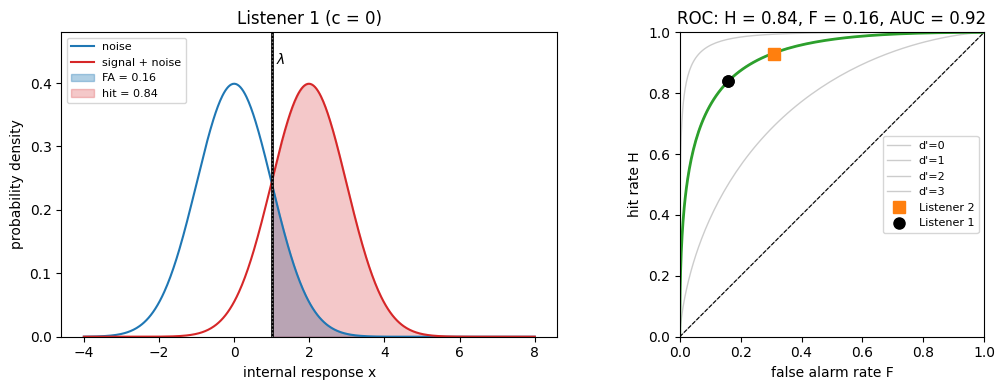

In [4]:
listeners = {'Listener 1': (0.84, 0.16), 'Listener 2': (0.93, 0.31)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, (H, F) in listeners.items():
    d, c = dprime_c(H, F)
    print(f"{name}: H = {H}, F = {F}  ->  d' = {d:.2f}, c = {c:.2f}")
d1, c1 = dprime_c(*listeners['Listener 1'])
plot_sdt(d1, c1, axes=axes, title='Listener 1 (c = 0)')
# add listener 2 as a second ROC point
H2, F2 = listeners['Listener 2']
axes[1].plot([F2], [H2], 's', color='tab:orange', ms=8, label='Listener 2')
axes[1].plot([listeners['Listener 1'][1]], [listeners['Listener 1'][0]], 'o', color='k', ms=8, label='Listener 1')
axes[1].legend(loc='center right', fontsize=8)
plt.tight_layout(); plt.show()

Both points lie on (almost) the same ROC curve: the listeners differ in **criterion**, not in sensitivity.

**Try:** in section 1 set $d'=2$ and move $c$ from $0$ to $-0.5$. Compare $H$ and $F$ with Listener 2.